# 06 - Formation Water & Environmental Corrections

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_a_foundations/06_formation_water_and_environment.ipynb)

**Part A - Petrophys Curriculum**

Before we can turn a resistivity log into a water saturation, we need to know two
"invisible" properties of the well: **how salty the formation water is**
(captured by its resistivity `Rw`) and **how hot the rock is** (the temperature
profile). Both are temperature-dependent, and both feed directly into Archie's
equation in lesson 07.

This lesson derives, for well **30_6-5**:
1. the **temperature profile** from a surface temperature and the header's
   bottom-hole temperature (BHT),
2. **mud filtrate resistivity `Rmf`**, cross-checked against the filtrate's
   chloride content and corrected to formation temperature,
3. **formation water resistivity `Rw`** by two independent routes - from salinity,
   and from the SP log - compared with the header value, which is the operator's
   evaluation value,
4. an **invasion characterization** from the deep vs. shallow resistivity curves.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals
- Read the **formation temperature profile** that `pp.interpret` builds from a
  surface temperature and the header bottom-hole temperature (BHT), and its
  geothermal gradient.
- Know how a resistivity is moved from its measurement temperature to formation
  temperature (the **Arps relation**), and why every Rw and Rmf needs its
  temperature.
- **Cross-check header values** (BHT, `RMF`, `RW`, filtrate chloride) against
  each other before trusting any of them, and give the workflow the value you
  trust (`rmf_chlorides_mg_l`, `rmf_meas_temp_f`, `rw`, `rw_meas_temp_f`,
  `salinity_ppm`).
- Estimate **`Rw`** from salinity and from the **SP** (`sp_rw_in_window`), and
  understand when each is trustworthy, including how a drifting SP baseline can
  fake a signal.
- Characterize **invasion** from `RDEP` vs `RSHA` with the workflow's
  `INVASION_RATIO`.
- See exactly **why Rw and temperature are prerequisites** for the saturation
  calculation that follows in lesson 07.

## Why this matters
Archie's equation for water saturation is

$$S_w^{\,n} = \frac{a\,R_w}{\phi^{\,m}\,R_t}$$

Two of those inputs are *environmental*, not measured by a single log:

- **`Rw`** - the resistivity of the formation water. Fresh water is resistive,
  brine is very conductive; get `Rw` wrong and `Sw` is wrong by `Rw^(1/n)` - a
  2x error in `Rw` moves `Sw` by ~41 % for n=2.
- **Temperature** - resistivity of any brine falls as it heats up (ions move more
  freely). Both `Rw` and `Rmf` must be quoted *at formation temperature*, so we
  need the temperature at every depth.

Everything in this lesson exists to pin those two numbers down honestly.

### Prerequisites
This lesson assumes lessons **01-02** (loading a well, plotting it). The
saturation math it feeds into is covered in **lesson 07**.

Teaching well: **30_6-5**. It carries `SP`, and the deep/medium/shallow
resistivity triplet `RDEP` / `RMED` / `RSHA` that we need for `Rw`-from-SP and for
invasion analysis. Its LAS `~Params` block also records a few environmental
values: a bottom-hole temperature (`BHT`, in degC), a mud-filtrate resistivity
(`RMF`), the filtrate's chloride content (`CLFL`, 20,366 mg/l), and a
formation-water resistivity (`RW`) with the temperature it is quoted at (`RWT`,
in degF). The `RW`/`RWT` pair is the operator's evaluation value as published in
the NPD well data. Note what is missing: no measurement temperature for `RMF`, and
no TD. Header values are a starting point, not gospel: this lesson checks each one
against the others before using it.

In [2]:
import pandas as pd
import petrophys as pp

pd.set_option("display.max_colwidth", None)   # show the trace's decisions in full
well = pp.read(pp.sample("30_6-5"), formations=pp.sample("formations_30_6-5"))
well.describe()["header_parameters"]

{'BHT': 126.0, 'RW': 0.07, 'RWT': 230.0, 'RMF': 0.08}

> **Note**
>
> This LAS labels its core saturations `SWC` and `SOC` as fractions, but they
> hold percentages. Petrophys divides them by 100 when it reads the core data and
> says so with a `UserWarning` each time. The next cell hides only those two
> messages; lesson 02 covers core-unit conversion.

In [3]:
import warnings

warnings.filterwarnings("ignore", message=r"(SWC|SOC): inferred percent core saturation")

## 1. Temperature profile from surface temperature and BHT

Formation temperature is assumed to rise linearly with depth:

`T(depth) = T_surface + gradient * depth`

`pp.interpret` builds this profile itself. It takes the surface temperature from
the setting `surface_temp_f` (default 68 degF), converts the header BHT from degC,
places it at total depth - here the deepest logged sample, since the header has no
TD - and writes the profile as the curve `TEMP`. The trace says what it did. We
interpret the well with no settings at all, so every environmental value comes from
the header, and read the three environmental steps of the trace:

In [4]:
result = pp.interpret(well)
{step: result.step(step).decisions for step in ["temperature", "rmf", "rw"]}

{'temperature': ['Temperature profile anchored to BHT metadata/input',
  'Gradient = 1.6354 F/100ft (29.81 C/km)',
  'Temp range: 77.5 - 258.8 F'],
 'rmf': ['Header CLFL (rmf_chlorides_mg_l=20366) not used: the header RMF is the direct measurement',
  'Rmf from LAS metadata used assumed reference temperature 75.0F and was corrected along the temperature profile'],
 'rw': ['Rw corrected from LAS metadata: 0.0700 ohm.m @ 230F along the temperature profile']}

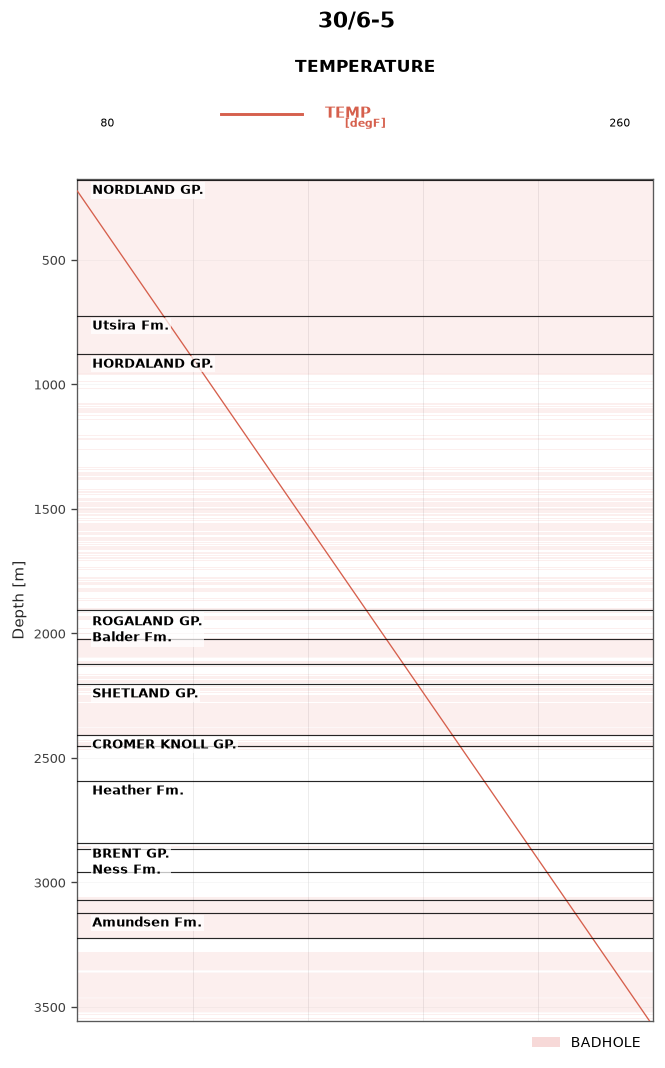

In [5]:
pp.plot(result, curves=["TEMP"], figsize=(5, 9))

#### Temperature context

The gradient in the trace, about 30 C/km (1.64 degF/100 ft), is typical of North
Sea basins, and the profile runs from 77.5 degF at the top of the log to the BHT,
258.8 degF, at its base.

A recorded BHT is usually read before the borehole has recovered from the
cooling effect of mud circulation, so it tends to *understate* the true formation
temperature. Treat the profile as a reasonable, slightly cool estimate; `bht_f`
or `gradient_f_per_100ft` replace the header value when you have a better one.

## 2. Mud filtrate resistivity `Rmf` at formation temperature

While drilling, mud filtrate invades the near-wellbore rock. Its resistivity
`Rmf` is measured on a filtrate sample at a stated temperature, and we need it at
*formation* temperature. Resistivity scales with temperature through the
**Arps relation**:

$$R_2 = R_1 \cdot \frac{T_1 + 6.77}{T_2 + 6.77}\quad(T \text{ in }^{\circ}F)$$

The header gives two facts about the filtrate: `RMF` = 0.08 ohm.m, *without* the
temperature it was measured at, and the filtrate chloride `CLFL`. The trace above
shows what the workflow did with them: it took `RMF` as the direct measurement and,
with no `RMFT` (or `MFST`) in the header, **assumed** it was measured at 75 degF.

The chloride is the more complete fact, because salinity does not depend on
temperature. Pass it as `rmf_chlorides_mg_l` (chlorides in mg/l, the mud-report
unit) and the workflow converts it to an NaCl salinity - x 58.44/35.45, the NaCl/Cl
mass ratio, then divided by the brine density to give ppm by weight (McCain,
1991) - and computes Rmf from it at any temperature. A header `CLFL` is read the
same way, but only after a header `RMF`, which is why the first run did not use it. A third run tests a hypothesis: that the
header `RMF` was measured hot, at 183 degF, rather than at 75 degF
(`rmf_meas_temp_f`).

In [6]:
rmf_runs = {
    "header RMF, 75 degF assumed": result,
    "filtrate chloride, 20,366 mg/l": pp.interpret(well, rmf_chlorides_mg_l=20366),
    "header RMF at 183 degF": pp.interpret(well, rmf_meas_temp_f=183),
}
{name: r.step("rmf").decisions[-1] for name, r in rmf_runs.items()}

{'header RMF, 75 degF assumed': 'Rmf from LAS metadata used assumed reference temperature 75.0F and was corrected along the temperature profile',
 'filtrate chloride, 20,366 mg/l': 'Rmf from mud-filtrate chlorides 20366 mg/l: NaCl equivalent 33574 mg/l (Cl x 58.44/35.45) = 32839 ppm at a brine density of 1.0224 g/cm3 -> 0.1897 ohm.m @ 75F and then along the temperature profile',
 'header RMF at 183 degF': 'Rmf corrected from LAS metadata: 0.0800 ohm.m @ 183F across the temperature profile'}

In [7]:
pd.concat({name: r.statistics(["RMF"], top=2841, bottom=2958) for name, r in rmf_runs.items()}).round(4)

,,unit,samples,mean,p10,median,p90
"header RMF, 75 degF assumed",RMF,ohm.m,768,0.0284,0.0281,0.0284,0.0287
"filtrate chloride, 20,366 mg/l",RMF,ohm.m,768,0.0673,0.0666,0.0673,0.0681
header RMF at 183 degF,RMF,ohm.m,768,0.0659,0.0652,0.0659,0.0666


#### Which Rmf to trust

The chloride gives 0.19 ohm.m at 75 degF, and about 0.067 ohm.m across the Brent
Group. Read as a 75 degF value, the header `RMF` gives less than half of that,
about 0.028 ohm.m: a filtrate far saltier than its own chloride says. Read at
183 degF, the header `RMF` gives 0.066 ohm.m, within 2 % of the chloride. So the
header value was most likely measured hot, and the 75 degF the workflow assumes
for a header Rmf without a temperature does not fit this well.

The chloride is a measured salinity, so it describes the filtrate unambiguously:
we carry the chloride-derived Rmf forward. Note how salty this filtrate is: about
as salty as sea water, which is typical of an offshore water-based mud. That
matters for the SP section below.

## 3. Formation water resistivity `Rw`

`Rw` is the star input. We compare three routes, each quoted at formation
temperature.

### 3a. From the header, and from salinity
The default run took the header `RW`, 0.070 ohm.m at `RWT` = 230 degF, and moved it
along the temperature profile (trace above). A formation-water salinity is the
alternative when no Rw is known: `salinity_ppm` gives Rw at every depth from the
Schlumberger NaCl relation, ahead of a header `RW`. A North Sea-like brine of
35,000 ppm:

In [8]:
salty = pp.interpret(well, salinity_ppm=35000)
rw_runs = {"header RW, 0.070 at 230 degF": result, "salinity 35,000 ppm": salty}
pd.concat({name: r.statistics(["TEMP", "RW"], top=2841, bottom=2958) for name, r in rw_runs.items()}).round(4)

unit  samples      mean       p10  \
header RW, 0.070 at 230 degF TEMP   degF      768  223.5696  221.0609   
                             RW    ohm.m      768    0.0720    0.0712   
salinity 35,000 ppm          TEMP   degF      768  223.5696  221.0609   
                             RW    ohm.m      768    0.0636    0.0629   

                                     median       p90  
header RW, 0.070 at 230 degF TEMP  223.5696  226.0783  
                             RW      0.0720    0.0727  
salinity 35,000 ppm          TEMP  223.5696  226.0783  
                             RW      0.0636    0.0643

Across the Brent Group, where the temperature runs from about 221 to 226 degF
(p10 to p90; 224 degF in the middle), the header Rw reads about 0.072 ohm.m and the
35,000 ppm brine about 0.064 ohm.m: within 13 % of each other, so the operator's
water is a little fresher than 35,000 ppm.

### 3b. From the SP log - and how baseline drift can fool it

Where a saline formation sits opposite a fresher mud filtrate, the SP deflects.
The static SP (SSP) relates `Rmf` and `Rw`:

`SSP = -K * log10(Rmf / Rw)`, with `K = 61 + 0.133 * T` (T in degF)

`sp_rw_in_window` (in `petrophys.interpretation.electrical.rw`) does this for a
depth window of a well: it moves `Rmf` from its measurement temperature to the
window's temperature, picks a clean-sand and a shale SP baseline inside the window,
takes their difference as the SSP, and inverts for `Rw`, quoted at the
`reference_temp_f` we ask for - here 224 degF, the middle of the Brent Group, so the
answers compare with the table above. It needs the filtrate (0.19 ohm.m at
75 degF, section 2) and the temperature at every depth, the `TEMP` curve of the
interpretation.

We run it twice: once on the **whole log** (about 3,400 m of section), and once on
a **local window**, 2800-2958 m: the Brent Group sands plus the Heather shale just
above them. Predict the answer first. The filtrate and the formation brine have
similar salinities, so `Rmf/Rw` is close to 1 and a genuine SSP should be only a few
mV.

In [9]:
from petrophys.interpretation.electrical.rw import sp_rw_in_window

temperature = result.well["TEMP"].data
pd.DataFrame([
    sp_rw_in_window(well, rmf=0.19, rmf_temp_f=75, temperature_f=temperature, reference_temp_f=224),
    sp_rw_in_window(well, rmf=0.19, rmf_temp_f=75, temperature_f=temperature, reference_temp_f=224,
                    top=2800, bottom=2958),
], index=["whole log", "2800-2958 m"])[["sp_clean_mv", "sp_shale_mv", "ssp_mv", "rw", "reference_temp_f"]].round(4)

,sp_clean_mv,sp_shale_mv,ssp_mv,rw,reference_temp_f
whole log,32.2739,77.4810,-45.2071,0.0193,224.0
2800-2958 m,59.3935,64.5438,-5.1503,0.0591,224.0


Where did the whole-log SSP come from? Plot the SP over the whole well:

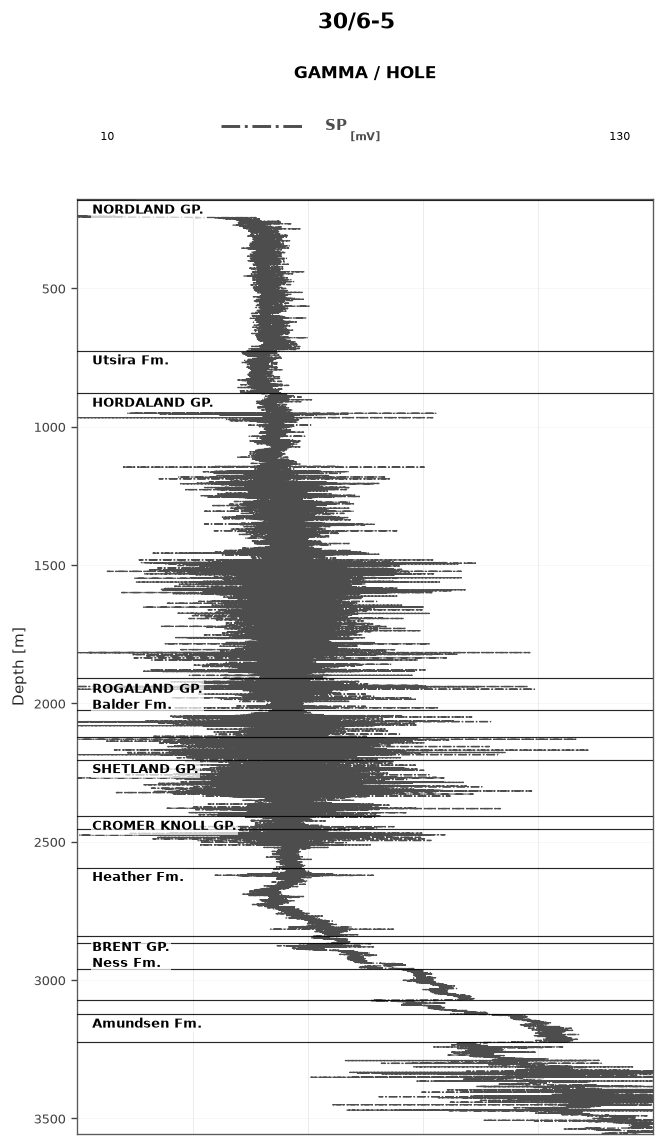

In [10]:
pp.plot(well, curves=["SP"], figsize=(5, 10))

#### Reading the two SP answers

The SP baseline is not constant: it drifts by tens of mV between the shallow
section and the deepest sands, steadily from the Heather Formation down. The
whole-log pick takes its clean line (about 32 mV) from the shallower section and
its shale line (about 77 mV) from the deeper shales, so the -45 mV "SSP" it
measures is mostly that drift. The Rw it returns, about 0.019 ohm.m, is a quarter
of the header value and would imply a brine several times saltier than the
filtrate or the operator's water.

The local pick compares sand with the shale right next to it. It finds a
deflection of only about -5 mV, as the salinities predict, and returns an Rw of
about 0.059 ohm.m, within 20 % of the header value. A small SSP means exactly
that: the formation water is about as salty as the filtrate.

Two caveats remain. With an SSP of only a few mV, a few mV of baseline noise is a
large relative error, so treat the local SP answer as a consistency check rather
than a measurement. And hydrocarbons suppress the SP deflection, so in the
oil-bearing Brent Group sands it may understate the true contrast. This drift is
also why the workflow keeps its own SP-derived clay volume out of `VCL` unless you
set both SP baselines.

### 3c. Reconcile the estimates

Quoted at the same temperature, about 224 degF in the Brent Group:

| estimate | Rw (ohm.m) |
|---|---|
| header RW, 0.070 at 230 degF | about 0.072 |
| salinity 35,000 ppm | about 0.064 |
| SP, local baselines | about 0.059 |
| SP, whole-log baselines | about 0.019 |

Three independent routes - the header (operator) value, an assumed North Sea
salinity and the local SP pick - agree within about 25 %. That is comfortably small
for saturation work: `Sw` scales with `Rw^(1/n)`, so a 25 % spread in Rw is about
12 % in `Sw` for n=2. One value does not fit: the **whole-log SP** answer, an
artefact of baseline drift.

The header `RW` is only usable because it comes with `RWT`. Here 230 degF is close
to the reservoir temperature, so ignoring it would cost little, but a header `RW`
quoted at a surface temperature such as 68-75 degF is several times higher than
the in-situ value and must be Arps-corrected before use. Lesson 07 meets exactly
that case in the carbonate well HW-3.

The following lessons therefore use **`Rw = 0.070` ohm.m at 230 degF**.
`pp.interpret` reads `RW` together with `RWT` from this header and corrects it
itself. For a well whose header lacks the temperature, pass the value *with its
temperature*: `pp.interpret(well, rw=0.07, rw_meas_temp_f=230)`. Without
`rw_meas_temp_f` the library takes the value as Rw at the well's median formation
temperature, and warns that it did; for a value measured at another temperature
that changes `Sw` strongly.

## 4. Invasion characterization (RDEP vs RSHA)

Resistivity tools read at different depths of investigation. Comparing a **deep**
curve (`RDEP`, reads the true, uninvaded formation `Rt`) with a **shallow** curve
(`RSHA`), used as a proxy for the flushed-zone `Rxo`, tells us about invasion and, indirectly,
about movable hydrocarbons.

The **invasion ratio** is `Rxo / Rt`, which the workflow writes as the curve
`INVASION_RATIO`:

- **ratio < 0.8 - conductive invasion:** the flushed zone is more conductive than
  the uninvaded rock; with a filtrate about as salty as the formation water, as
  here, that usually means filtrate has displaced hydrocarbon.
- **0.8 <= ratio <= 1.2 - minimal invasion:** little contrast (`Rmf` ~ `Rw` in
  water-bearing rock).
- **ratio > 1.2 - resistive invasion:** the flushed zone is more resistive,
  typically a fresher filtrate invading saline formation water.

Invasion needs permeability, so these classes only mean invasion in permeable
rock. The display window, 2350-2950 m, runs from the overlying shales down
through the Brent Group (2841-2958 m).

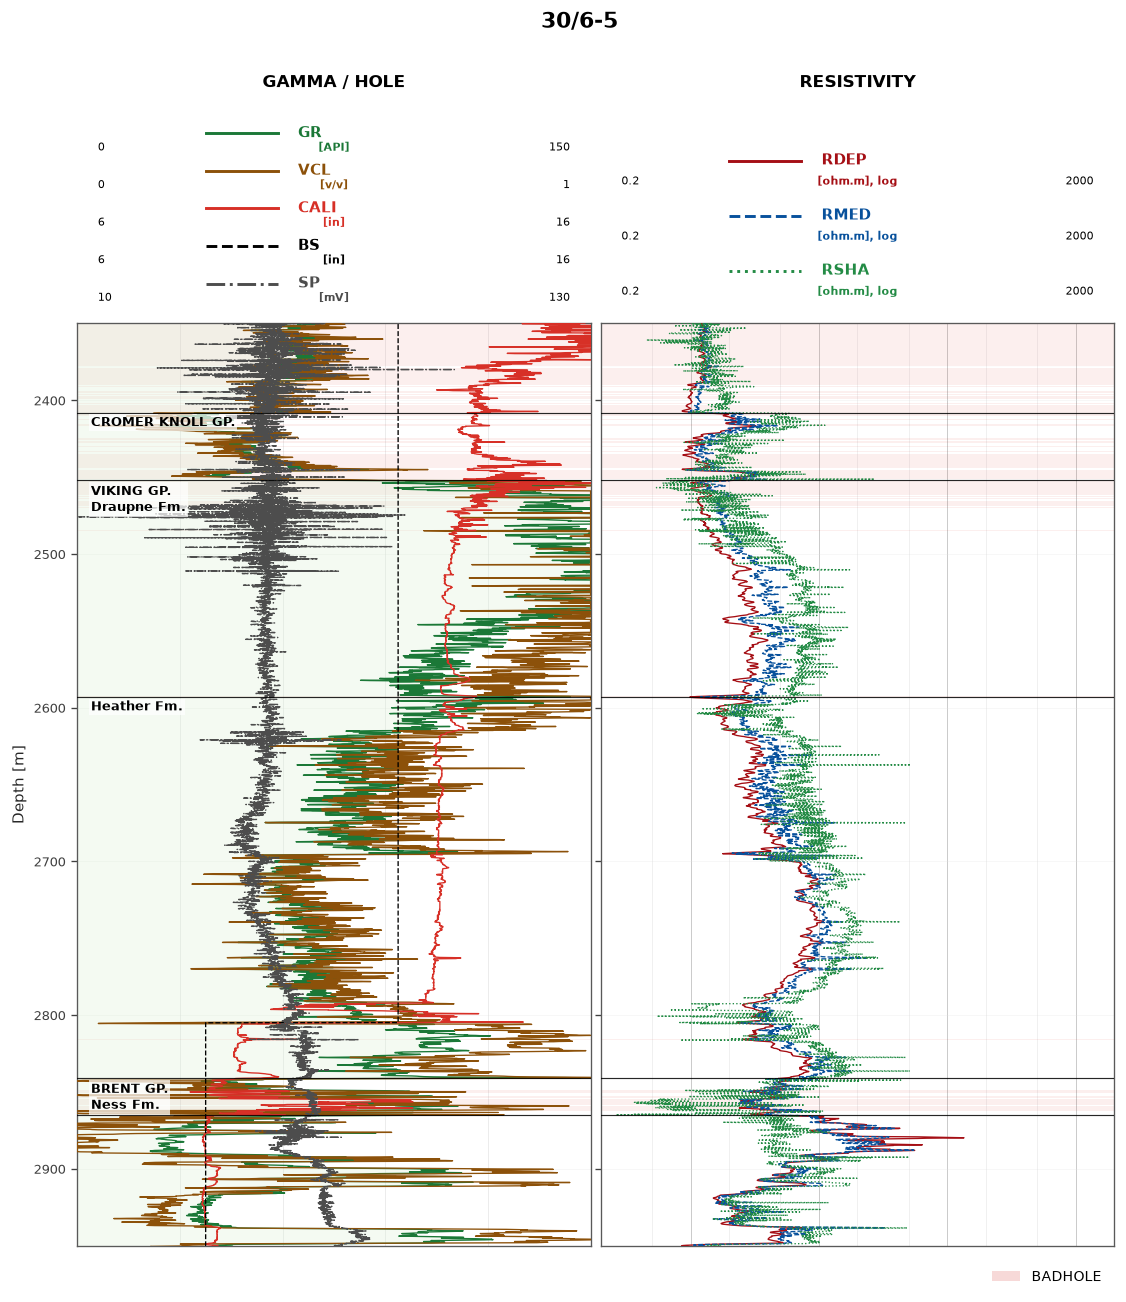

In [11]:
pp.plot(result, top=2350, bottom=2950, tracks=["GAMMA / HOLE", "RESISTIVITY"], figsize=(9, 11))

To read invasion only in permeable rock, take the Brent Group sands (GR below
60 API) and the share of each invasion class above and below 2900 m, where the
deep resistivity drops:

In [12]:
sands = result.well.to_dataframe().query("2841 <= DEPTH <= 2958 and GR < 60")
classes = pd.cut(sands["INVASION_RATIO"], [0, 0.8, 1.2, float("inf")], labels=["conductive", "minimal", "resistive"])
pd.crosstab(pd.cut(sands["DEPTH"], [2841, 2900, 2958]), classes, normalize="index", margins=True).round(2)

INVASION_RATIO,conductive,minimal,resistive
DEPTH,,,
"(2841, 2900]",0.78,0.14,0.08
"(2900, 2958]",0.03,0.29,0.68
All,0.40,0.22,0.38


#### Reading the invasion track

Read the separation only where the rock can take filtrate. Above the reservoir,
through the Viking Group shales (about 2450-2841 m), the shallow curve reads
above the deep curve over long stretches. Shale is effectively impermeable, so
that separation is not invasion: it reflects how differently the tools respond to
shale and to the borehole.

In the Brent Group sands the separation follows the fluids:

- **Above about 2900 m**, where the deep resistivity is high, most sand samples
  (about three quarters) are conductive: the flushed zone is more conductive than
  the uninvaded rock. Because the filtrate is about as salty as the formation
  water, the likely cause is filtrate displacing hydrocarbon near the wellbore -
  evidence that the hydrocarbon there is moveable.
- **Below about 2900 m**, where the deep resistivity falls to a few ohm.m, about
  two thirds of the sand samples show mild resistive separation. That is what
  water-bearing sand shows when the filtrate is slightly fresher than the
  formation water - consistent with the small SSP of the local SP pick.

## 5. How this feeds the saturation calculation

Pulling it together, lesson 07's saturation run will need:

| input | where it came from here |
|---|---|
| **`Rw`** | the header (operator) 0.070 ohm.m at 230 degF, cross-checked against a salinity estimate and a local SP pick at one temperature |
| **formation temperature** | linear profile from the header BHT, the `TEMP` curve |
| **`Rmf`** | filtrate chloride (`CLFL`, 20,366 mg/l), moved along the temperature profile: `rmf_chlorides_mg_l=20366` |
| **`Rt`** | deep resistivity `RDEP` |
| invasion context | `INVASION_RATIO` in the sands, to know where filtrate matters |

In one call, with every value given with its temperature or as a salinity, so
nothing is assumed:

```python
pp.interpret(well, rw=0.07, rw_meas_temp_f=230, rmf_chlorides_mg_l=20366)
```

Without a temperature-consistent `Rw`, the saturation numbers are meaningless -
that is why this environmental step comes *before* saturation, not after.

## Pitfalls & parameter choices
- **Temperature drives resistivity.** Every `Rw`/`Rmf` must be quoted at formation
  temperature. A wrong gradient shifts `Rw` and hence `Sw` systematically, and a
  recorded BHT usually reads a little low.
- **A resistivity without its temperature is half a fact.** This header gives
  `RMF` with no measurement temperature (`RW` comes with `RWT`). Cross-check against
  anything temperature-independent (the filtrate chloride, a water analysis) before use.
- **Header values must agree with each other.** The header `RMF` matches its own
  filtrate chloride only if it was measured at about 183 degF, far above a normal
  surface measurement. Check that header values are consistent with each other and
  with physics before trusting any of them.
- **The SP method needs a salinity contrast and a stable baseline.** It fails in
  shale, when filtrate and formation water are similarly salty (as here), with
  KCl or oil-based mud, and when the baseline drifts. Pick the clean and shale
  lines locally, and check the SSP magnitude: a few mV of deflection cannot
  support a precise `Rw`.
- **Salinity is often a guess.** If you have a produced-water analysis or an
  offset well `Rw`, prefer it.
- **Invasion needs true shallow/deep curves and permeable rock.** With only
  `RMED` as a proxy the contrast is muted (the invasion step says where it fell
  back to a medium proxy), and separation in shale is not invasion.
- **OBM has no `Rmf`.** Oil-based mud does not conduct; the SP/`Rmf` workflow does
  not apply and you fall back to a known or offset `Rw`. With `mud_type='OBM'`,
  `pp.interpret` takes Rw from `rw=`, a header `RW` or a stated salinity, never
  from the SP or `Rxo/Rt`; without any of those it falls back to the apparent Rw
  of the clean, porous samples (P5 of `Rt * PHIE^m / a`), with a warning. It
  computes no `Sxo` or moveable-hydrocarbon index for oil-based mud.

## Recap
- A **linear temperature profile** from surface T + the header BHT gives formation
  temperature at every depth - the backbone for all resistivity corrections;
  `pp.interpret` writes it as `TEMP`.
- **Arps** rescales resistivity between temperatures; the workflow moves `Rw` and
  `Rmf` along the profile, from the temperature you give (`rw_meas_temp_f`,
  `rmf_meas_temp_f`) or from a salinity or chloride (`salinity_ppm`, `rmf_chlorides_mg_l`).
- **Header values need cross-checking:** the filtrate chloride pins `Rmf`, and the
  header `RW` (0.070 ohm.m at `RWT` 230 degF) agrees with the salinity and local SP
  estimates once all are quoted at one temperature.
- **`Rw`** can be had from **salinity** or from the **SP log**; quoted at the
  same temperature, agreement between them (and with the operator's value) is
  your confidence check. A whole-log SP pick can be dominated by baseline drift;
  pick SP baselines locally.
- The **invasion ratio** `Rxo/Rt` (`INVASION_RATIO`) classifies each depth as
  conductive / minimal / resistive invasion; in permeable sands a conductive
  flushed zone flags moveable hydrocarbon.
- All of this exists to hand a temperature-consistent **`Rw`** (and `Rt`, `T`) to
  the **saturation** calculation in lesson 07.

## Try it yourself
> **Exercise 1.** Interpret with a hotter BHT, `bht_f=300` (allowing for a BHT that
> has not recovered from circulation). How much do the Brent Group temperature,
> `RMF` and `RW` move?
>
> **Exercise 2.** Interpret with `salinity_ppm` from 20,000 to 120,000 and compare
> the Brent Group `RW` with the header value. Which salinity reproduces the
> operator's Rw?
>
> **Exercise 3.** Move the local SP window: try 2593-2958 m (all of the Heather
> shale plus the Brent Group), then 3071-3223 m (around the Cook sand). How stable is the
> SP-derived `Rw` at 224 degF?
>
> **Exercise 4.** Plot `INVASION_RATIO` with `pp.plot(result, curves=["GR", "INVASION_RATIO"], top=2841, bottom=2958)`.
> Do the conductive streaks line up with the low-GR Brent Group sands?

## What's next
Part A continues. In **07 - Water Saturation** we combine everything - clay
volume, porosity, the mineral model, and the `Rw`/temperature derived here - to
compute **water saturation**; **08 - Permeability** and **09 - Reservoir Quality
& Net Pay** then finish Part A.